Fait par :

Mathura SANTHALINGAM

Vidur PARAKARAN

# TP 2 - Visualisation

#### Importations

In [ ]:
import numpy as np
from sklearn.preprocessing import *
from sklearn import datasets
import matplotlib.pyplot as plt
from sklearn.decomposition import *
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.decomposition import PCA

### A. Normalisation de données

#### Création de la matrice X

In [ ]:
X = [
    [1 , -1, 2],
    [2, 0, 0],
    [0, 1, -1]
]
X = np.array(X)
print(f"Matrice : \n{X}\n")

mean_value = np.mean(X)
print(f"Moyenne : {mean_value}")
var_value = np.var(X)
print(f"Variance : {var_value}")

Matrice : 
[[ 1 -1  2]
 [ 2  0  0]
 [ 0  1 -1]]

Moyenne : 0.4444444444444444
Variance : 1.1358024691358024


#### Création de la matrice échelonnée

In [ ]:
X_scaled = scale(X)
print(f"Matrice Normalisée :\n{X_scaled}\n")

mean_value_scaled = np.mean(X_scaled)
print(f"Moyenne de X normalisé : {mean_value_scaled}\n")

std_value_scaled = np.std(X_scaled)
print(f"Variance de X normalisé : {std_value_scaled}\n")

Matrice Normalisée :
[[ 0.         -1.22474487  1.33630621]
 [ 1.22474487  0.         -0.26726124]
 [-1.22474487  1.22474487 -1.06904497]]

Moyenne de X normalisé : 4.9343245538895844e-17

Variance de X normalisé : 1.0



**Réponse A.3 :** On constate que les valeurs de la matrice X_scaled ont bien été normalisées ((X-moyenne)/ecart-type)

**Réponse A.4 :** La moyenne est proche de 0 et l'écart-type est égal à 1, ce qui montre que notre matrice est bien échelonnée réduite. Ainsi, une caractéristique avec une variance disproportionnément grande ne dominera pas la fonction objective et donc ne va pas fausser l'apprentissage de l'algorithme.

### B. Normalisation MinMax

In [ ]:
X2 = [
    [1 , -1, 2],
    [2, 0, 0],
    [0, 1, -1]
]
X2 = np.array(X2)
print(f"Matrice X2 :\n {X2}\n")

mean_variables = np.mean(X2, axis=0)
print(f"Moyenne : {mean_variables}\n")

scaler = MinMaxScaler()
X2_scaled = scaler.fit_transform(X2)
print(f"Matrice X2 normalisé :\n {X2_scaled}\n")

mean_variables_scaled = np.mean(X2_scaled, axis=0)
print(f"Moyenne des variables de X2 normalisé :\n {mean_variables_scaled}")

Matrice X2 :
 [[ 1 -1  2]
 [ 2  0  0]
 [ 0  1 -1]]

Moyenne : [1.         0.         0.33333333]

Matrice X2 normalisé :
 [[0.5        0.         1.        ]
 [1.         0.5        0.33333333]
 [0.         1.         0.        ]]

Moyenne des variables de X2 normalisé :
 [0.5        0.5        0.44444444]


**Réponse B.3 :** On a redimensionné les valeurs pour qu'elles soient comprises entre 0 et 1 : la plus petite valeur de la matrice d'origine devient 0, et la plus grande devient 1, on a donc une nouvelle moyenne qui ne se rapprochent plus de 0.

### C. Visualisation de données

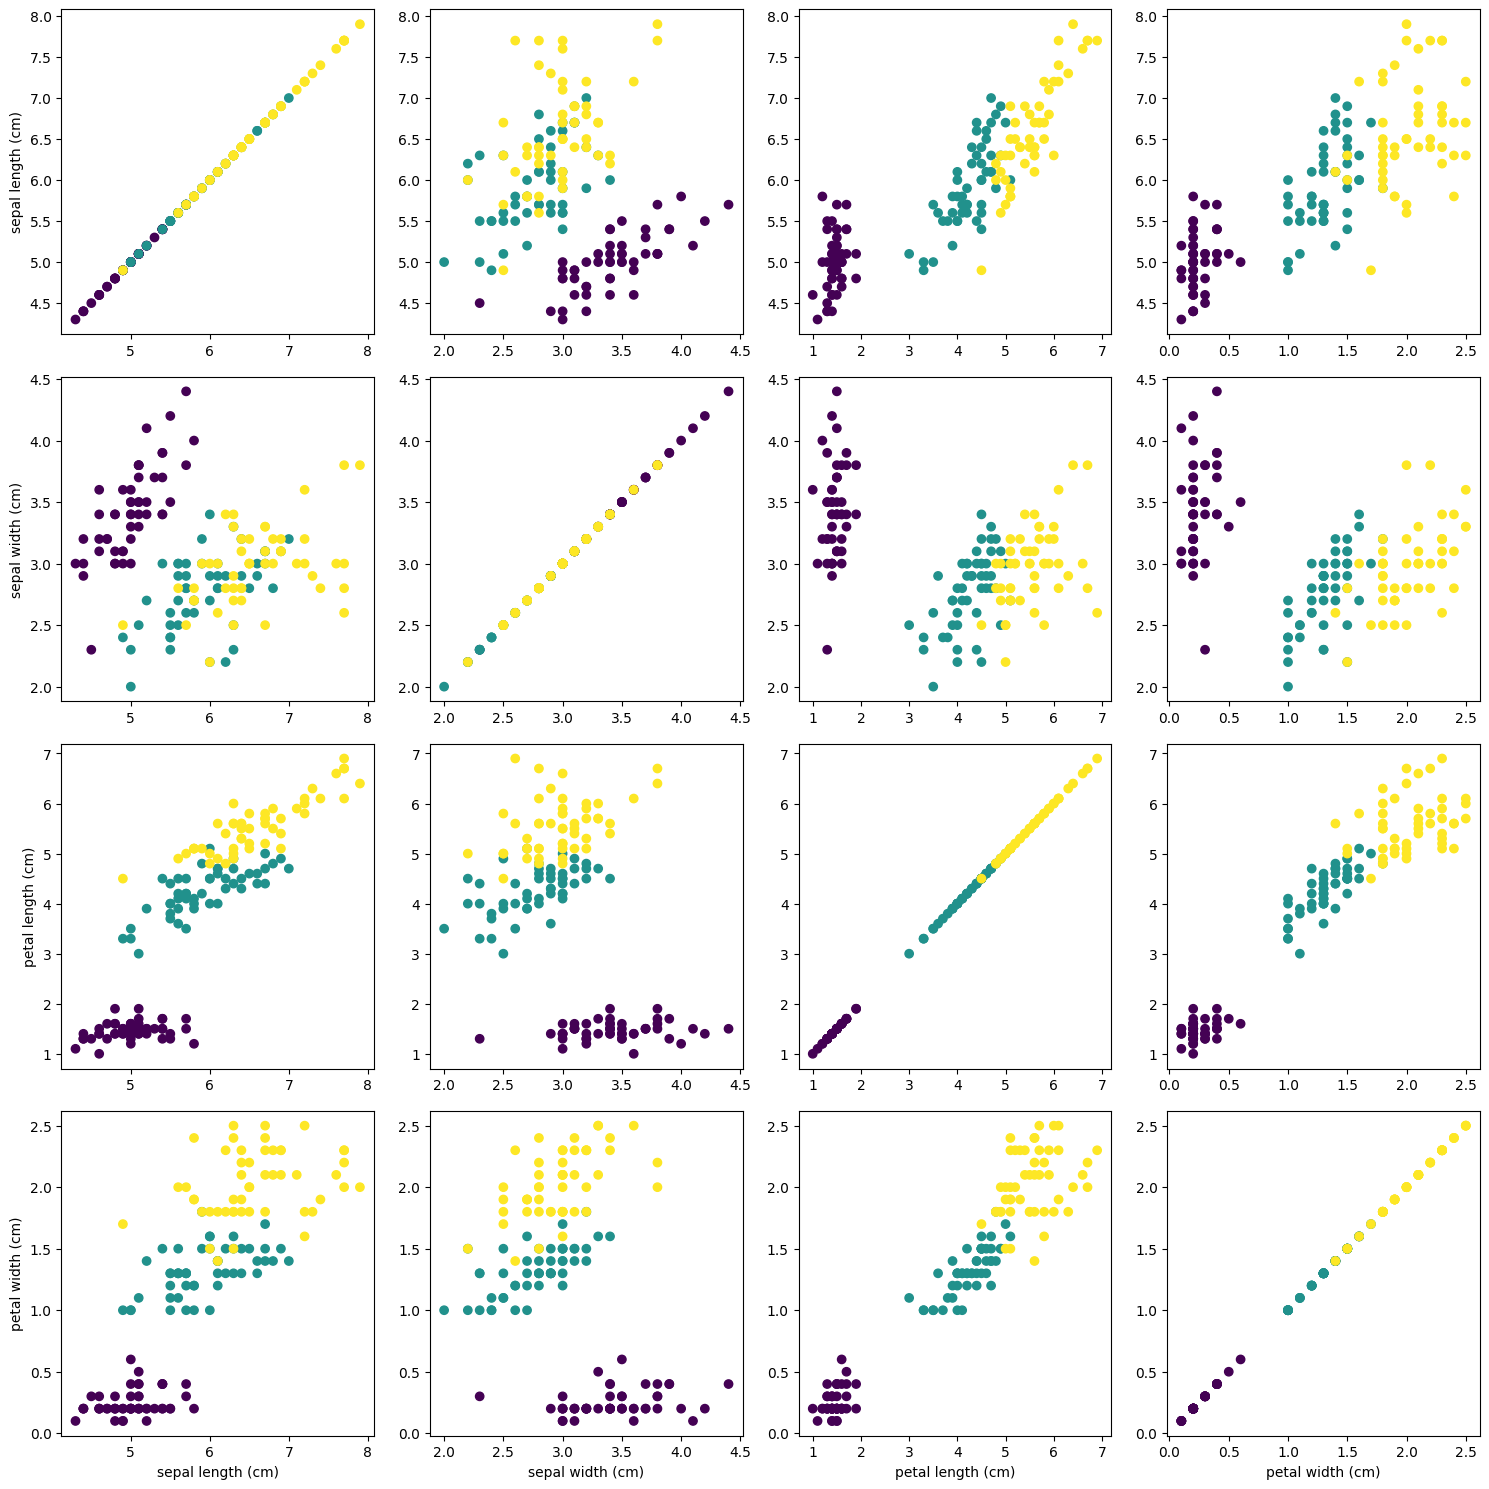

In [ ]:
iris = datasets.load_iris()

X = iris.data
y = iris.target
noms_variables = iris.feature_names

fig, axes = plt.subplots(4, 4, figsize=(15, 15))

for i in range(4):
    for j in range(4):
        axes[i, j].scatter(X[:, j], X[:, i], c=y, cmap='viridis')
        
        if i == 3:
            axes[i, j].set_xlabel(noms_variables[j])
        if j == 0:
            axes[i, j].set_ylabel(noms_variables[i])

plt.tight_layout()
plt.show()

**Réponse C.2 :** La meilleure visualisation est 'petal length' x 'petal width' (ou sa symetrie) car on a une forte corrélation positive entre les caractéristiques.

### D. Réduction de dimensions et visualisation de données

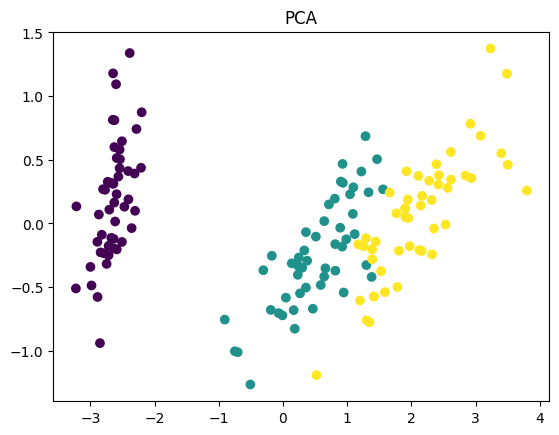

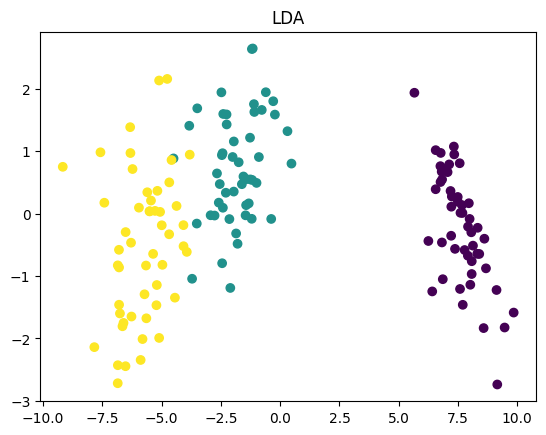

In [ ]:
pca = PCA()
IrisPCA  = pca.fit(iris.data).transform(iris.data)

lda = LDA()
IrisLDA = lda.fit(iris.data, iris.target).transform(iris.data)

plt.scatter(IrisPCA[:, 0], IrisPCA[:, 1], c=y, cmap='viridis')
plt.title("PCA")
plt.show()

plt.scatter(IrisLDA[:, 0], IrisLDA[:, 1], c=y, cmap='viridis')
plt.title("LDA")
plt.show()

**Réponse D.3 :** On constate que la visualisation basée sur la LDA distingue mieux les 3 classes. En effet, la LDA étant supervisée, on a la distance entre les points intra-classes qui diminue et la distance entre les points inter-classes qui augmente, ce qui donne une meilleure visualisation des classes.